# Chapitre 9 - Exercices 9.1 à 9.3 : lisseurs linéaires et backfitting

Ces trois exercices étudient le backfitting (algorithme 9.1 du livre) sous l'angle de
l'**algèbre linéaire** : quand les lisseurs sont linéaires, $\hat{\mathbf f}_j = S_j\,
\mathbf r$, l'algorithme devient une méthode itérative classique de résolution d'un
système linéaire.

- **Exercice 9.1** : une spline de lissage préserve la partie linéaire de l'ajustement ;
  conséquence pour le recentrage dans le backfitting.
- **Exercice 9.2** : le backfitting est un algorithme de Gauss–Seidel par blocs ;
  convergence pour deux lisseurs symétriques.
- **Exercice 9.3** : avec des projections orthogonales, les équations du backfitting
  sont les équations normales des moindres carrés.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.ch09_arbres import (SplineLisseur, MatriceLisseur, local_linear_matrix,
                             backfitting)

set_style()
rng = np.random.RandomState(0)

## Exercice 9.1 : La spline de lissage préserve la partie linéaire

**Énoncé (reformulé).** Décomposons la réponse en $y_i = \hat y_i + r_i$, où $\hat y$
est l'ajustement de la régression linéaire simple de $y$ sur $x$ et $r$ le résidu.
Soit $S$ la matrice de lissage d'une spline de lissage. Montrer que
$$S y = \hat y + S r,$$
c'est-à-dire que la spline reproduit exactement la partie linéaire. Montrer qu'il en va
de même pour la régression linéaire locale (section 6.1.1). En déduire que l'étape de
recentrage (seconde ligne de l'étape 2 de l'algorithme 9.1) est inutile.

### Rappels

- **Spline de lissage** (section 5.4) : $\hat f$ minimise $\sum_i(y_i-f(x_i))^2 +
  \lambda\int f''^2$. Dans une base $B_1,\dots,B_K$ de splines contenant les fonctions
  affines, $f=\sum_k c_kB_k$, on a $\hat c = (B^TB+\lambda\Omega)^{-1}B^Ty$ et
  $S=B(B^TB+\lambda\Omega)^{-1}B^T$, avec $\Omega_{kl}=\int B_k''B_l''$.
- **Régression linéaire locale** (éq. (6.7)-(6.9)) : en chaque point $x_0$, on résout
  $\min_{\alpha,\beta}\sum_i K_\lambda(x_0,x_i)\,(y_i-\alpha-\beta x_i)^2$ et l'on pose
  $\hat f(x_0)=\hat\alpha(x_0)+\hat\beta(x_0)x_0$. Matriciellement, avec $\mathbf B$ la
  matrice $N\times 2$ de lignes $(1,x_i)$ et $W(x_0)=\mathrm{diag}(K_\lambda(x_0,x_i))$ :
  $\hat f(x_0) = (1,x_0)\,(\mathbf B^TW(x_0)\mathbf B)^{-1}\mathbf B^TW(x_0)\,y$.

### Solution : le cas de la spline de lissage

Le vecteur $\hat y$ est de la forme $\hat y_i = a + b x_i$ : ce sont les valeurs aux
$x_i$ de la fonction affine $\ell(x)=a+bx$.

**Étape 1 : $S\hat y = \hat y$.** Appliquons la spline de lissage aux données
$(x_i,\hat y_i)$. Pour la fonction $\ell$ :
- le terme d'ajustement $\sum_i(\hat y_i-\ell(x_i))^2$ vaut $0$ ;
- le terme de pénalité $\lambda\int\ell''^2$ vaut $0$ car $\ell''=0$.

Le critère étant toujours $\ge 0$, $\ell$ en est un minimiseur ; le critère étant
strictement convexe (pour $\lambda>0$ et au moins deux valeurs distinctes de $x$), c'est
**le** minimiseur. Donc la spline ajustée à $\hat y$ est $\ell$ elle-même : $S\hat y =
\hat y$.

**Étape 2 : linéarité.** $S$ est une matrice, donc par linéarité
$$Sy = S(\hat y + r) = S\hat y + Sr = \hat y + Sr. \qquad\blacksquare$$

En d'autres termes, la spline ne touche pas à la partie linéaire de $y$ et ne lisse que
le résidu $r$.

### Solution : le cas de la régression linéaire locale

Même raisonnement : si $y = \hat y$ avec $\hat y_i = a+bx_i$, alors en chaque point
$x_0$ le problème des moindres carrés pondérés locaux admet la solution exacte
$(\alpha,\beta)=(a,b)$ (somme des carrés nulle). La matrice $\mathbf B^TW(x_0)\mathbf B$
étant inversible (au moins deux points de poids non nul), cette solution est unique. Donc
$\hat f(x_0)=a+bx_0$ pour tout $x_0$ : $S\hat y=\hat y$, puis $Sy=\hat y+Sr$ par
linéarité.

Algébriquement : $(\mathbf B^TW\mathbf B)^{-1}\mathbf B^TW\,\mathbf B\,(a,b)^T = (a,b)^T$,
d'où $\hat f(x_0) = (1,x_0)(a,b)^T$.

### Vérification numérique

In [2]:
N = 80
x = np.sort(rng.uniform(0, 1, N))
y = np.sin(5 * x) + 2 * x + 0.3 * rng.randn(N)
A = np.column_stack([np.ones(N), x])
y_lin = A @ np.linalg.lstsq(A, y, rcond=None)[0]
r = y - y_lin

S_spl = SplineLisseur(x, df=6).matrix()        # spline de lissage exacte (nœuds en tous les x_i)
S_ll = local_linear_matrix(x, bandwidth=0.08)  # régression linéaire locale
for nom, S in [("spline de lissage", S_spl), ("linéaire locale", S_ll)]:
    print("%-18s : max |S y - (y_lin + S r)| = %.2e" % (nom, np.abs(S @ y - (y_lin + S @ r)).max()))

spline de lissage  : max |S y - (y_lin + S r)| = 1.43e-10
linéaire locale    : max |S y - (y_lin + S r)| = 5.55e-15


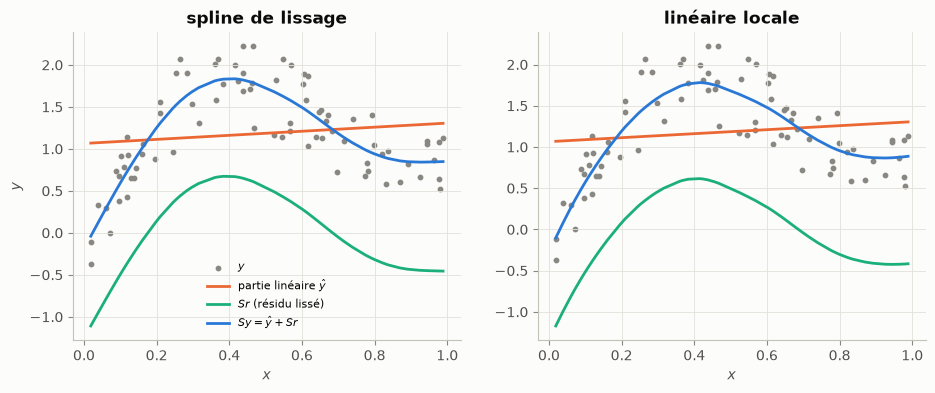

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nom, S) in zip(axes, [("spline de lissage", S_spl), ("linéaire locale", S_ll)]):
    ax.scatter(x, y, s=10, color=GRAY, label="$y$")
    ax.plot(x, y_lin, color=ORANGE, label=r"partie linéaire $\hat y$")
    ax.plot(x, S @ r, color=COLORS[2], label="$Sr$ (résidu lissé)")
    ax.plot(x, S @ y, color=BLUE, label="$Sy = \\hat y + Sr$")
    ax.set(title=nom, xlabel="$x$")
axes[0].set_ylabel("$y$")
axes[0].legend(fontsize=8)
plt.show()

### Conséquence pour le backfitting

Dans l'algorithme 9.1, on applique $S_j$ à des résidus partiels $\mathbf r$ et l'on
recentre le résultat pour que $\sum_i\hat f_j(x_{ij})=0$. Si $\mathbf r$ est de
moyenne nulle, le recentrage est-il nécessaire ?

Décomposons $\mathbf r = \hat{\mathbf r} + \mathbf e$ (partie linéaire + résidu de la
régression linéaire de $\mathbf r$ sur $x_j$). Alors :
- $\hat{\mathbf r}$ est de moyenne $\bar r = 0$ (une régression avec constante
  reproduit la moyenne) ;
- $\mathbf e$ est orthogonal à $\mathbf 1$ et à $x_j$ (équations normales).

D'après ce qui précède, $S_j\mathbf r = \hat{\mathbf r} + S_j\mathbf e$. Il reste à voir
que $S_j\mathbf e$ est de moyenne nulle.

**Pour la spline de lissage**, $S$ est **symétrique** et $S\mathbf 1 = \mathbf 1$ (les
constantes sont des fonctions affines). Donc
$$\mathbf 1^TS\mathbf e = (S^T\mathbf 1)^T\mathbf e = (S\mathbf 1)^T\mathbf e =
\mathbf 1^T\mathbf e = 0 .$$
Ainsi $\mathbf 1^TS_j\mathbf r = \mathbf 1^T\hat{\mathbf r} + 0 = 0$ : lisser une
réponse de moyenne nulle donne un ajustement de moyenne nulle. Comme $\hat\alpha=\bar y$
et que les $\hat f_k$ sont initialement nulles, tous les résidus partiels sont de moyenne
nulle et, par récurrence, toutes les $\hat f_j$ le restent : **le recentrage est
inutile** (en arithmétique exacte).

> **Remarque.** On peut aussi le voir sur les équations normales de la spline,
> $B^T(y-B\hat c)=\lambda\Omega\hat c$. Si $\ell=Ba$ est affine, sa pénalité est nulle,
> $a^T\Omega a=0$, donc $\Omega a=0$ ($\Omega$ étant symétrique positive). En multipliant
> par $a^T$ : $\ell^T(y-Sy)=\lambda a^T\Omega\hat c=0$. Les résidus d'une spline de
> lissage sont **orthogonaux aux fonctions affines**, en particulier à $\mathbf 1$.

**Pour la régression linéaire locale**, $S$ n'est **pas symétrique** : on a toujours
$S\mathbf 1=\mathbf 1$ (chaque ligne somme à 1), mais en général $\mathbf 1^TS \ne
\mathbf 1^T$, de sorte que $\mathbf 1^TS\mathbf e$ n'a aucune raison d'être nul. La
préservation de la partie linéaire reste vraie, mais elle ne suffit pas à garantir des
ajustements de moyenne nulle : pour ce type de lisseur, le recentrage est réellement
utile (même si l'écart est en général faible).

In [4]:
r0 = y - y.mean()
print("moyenne de r                 : %.2e" % r0.mean())
print("moyenne de S r (spline)       : %.2e" % (S_spl @ r0).mean())
print("moyenne de S r (lin. locale)  : %.2e" % (S_ll @ r0).mean())
print("S symétrique ? spline : %s, linéaire locale : %s"
      % (np.allclose(S_spl, S_spl.T), np.allclose(S_ll, S_ll.T)))

moyenne de r                 : 5.00e-17
moyenne de S r (spline)       : -1.31e-11
moyenne de S r (lin. locale)  : -2.24e-02
S symétrique ? spline : True, linéaire locale : False


Vérifions sur un backfitting à deux variables **sans recentrage** : avec des splines,
les $\hat f_j$ restent de moyenne nulle (à l'arrondi près) ; avec la régression linéaire
locale, elles dérivent.

In [5]:
x1, x2 = rng.uniform(0, 1, N), rng.uniform(0, 1, N)
yy = np.sin(4 * x1) + (x2 - 0.5) ** 2 + 0.2 * rng.randn(N)
yy = yy - yy.mean()

class SansCentrage:
    """Lisseur utilisé avec intercept=False : pas de recentrage."""
    def __init__(self, S):
        self.S = S
    def fit(self, r, w=None):
        return self.S @ r

for nom, mats in [("spline", [SplineLisseur(v, df=4).matrix() for v in (x1, x2)]),
                  ("linéaire locale", [local_linear_matrix(v, 0.1) for v in (x1, x2)])]:
    _, F, it = backfitting(yy, [SansCentrage(S) for S in mats], intercept=False,
                           tol=1e-10, max_iter=500)
    print("%-16s : moyennes des f_j = %s" % (nom, np.array2string(F.mean(0), precision=2)))

spline           : moyennes des f_j = [ 1.02e-11 -1.39e-11]
linéaire locale  : moyennes des f_j = [-23.47  23.48]


> **À retenir.** Un lisseur qui reproduit les fonctions affines vérifie $Sy=\hat y+Sr$ :
> il ne lisse que l'écart à la droite des moindres carrés. Pour une spline de lissage
> (lisseur symétrique), on en déduit qu'une réponse centrée donne un ajustement centré,
> donc que le recentrage de l'algorithme 9.1 est inutile en théorie - il ne sert qu'à
> corriger les erreurs d'arrondi. Pour un lisseur non symétrique (linéaire local), il
> reste utile.

## Exercice 9.2 : Le backfitting est un algorithme de Gauss–Seidel

**Énoncé (reformulé).** Soit $A$ une matrice $k\times k$, $b\in\mathbb R^k$ connus, et
$z\in\mathbb R^k$ inconnu. L'algorithme de **Gauss–Seidel** pour résoudre $Az=b$ résout
successivement la $j$-ième équation en $z_j$, les autres coordonnées étant fixées à leurs
valeurs courantes, pour $j=1,\dots,k,1,\dots,k,\dots$ jusqu'à convergence.

(a) On considère un modèle additif à $N$ observations et $p$ termes, le $j$-ième étant
ajusté par un lisseur linéaire $S_j$, et le système (éq. (9.33))
$$\begin{pmatrix} I & S_1 & S_1 & \cdots & S_1\\ S_2 & I & S_2 & \cdots & S_2\\ \vdots
& & \ddots & & \vdots\\ S_p & S_p & S_p & \cdots & I\end{pmatrix}
\begin{pmatrix} \mathbf f_1\\ \mathbf f_2\\ \vdots\\ \mathbf f_p\end{pmatrix} =
\begin{pmatrix} S_1\mathbf y\\ S_2\mathbf y\\ \vdots\\ S_p\mathbf y\end{pmatrix},$$
où $\mathbf f_j\in\mathbb R^N$ contient les valeurs de la $j$-ième fonction aux points
de données. Montrer que le backfitting est un algorithme de Gauss–Seidel **par blocs**
pour ce système.

(b) Soient $S_1$, $S_2$ deux lisseurs **symétriques** à valeurs propres dans $[0,1)$.
Montrer que le backfitting à deux termes converge quelles que soient les valeurs
initiales, et donner la limite.

### Rappel : la méthode de Gauss–Seidel

Pour $Az=b$, on écrit la $j$-ième équation $\sum_l A_{jl}z_l = b_j$ et on la résout en
$z_j$ : $z_j \leftarrow \big(b_j - \sum_{l\ne j}A_{jl}z_l\big)/A_{jj}$, en utilisant
pour les $z_l$ les valeurs **les plus récentes** (celles déjà mises à jour dans le cycle
courant pour $l<j$). La version **par blocs** fait de même avec des blocs de
coordonnées $z_j\in\mathbb R^N$ et des blocs diagonaux $A_{jj}$ inversibles.

### (a) Solution

Le $j$-ième bloc-ligne du système (9.33) s'écrit
$$\mathbf f_j + S_j\sum_{k\ne j}\mathbf f_k = S_j\mathbf y .$$
Le bloc diagonal est l'identité ; résoudre ce bloc-ligne en $\mathbf f_j$, les autres
blocs étant fixés, donne
$$\mathbf f_j \leftarrow S_j\mathbf y - S_j\sum_{k\ne j}\mathbf f_k = S_j\Big(\mathbf y -
\sum_{k\ne j}\mathbf f_k\Big),$$
par linéarité de $S_j$. C'est exactement la mise à jour du backfitting : on lisse les
résidus partiels. En balayant $j=1,\dots,p$ avec les valeurs les plus récentes des
$\mathbf f_k$, on obtient bien un cycle de Gauss–Seidel par blocs. $\blacksquare$

(Ici $\mathbf y$ joue le rôle de $\mathbf y-\hat\alpha\mathbf 1$ ; on travaille avec une
réponse centrée et sans recentrage, ce qui ne change rien au raisonnement.)

**Vérification numérique.** On construit explicitement le grand système $Np\times Np$,
on lui applique Gauss–Seidel par blocs, et l'on compare, itération par itération, avec
notre fonction `backfitting`. Les lisseurs sont des splines avec un petit terme de
« ridge » (valeurs propres dans $[0,1)$), ce qui rend le système inversible.

In [6]:
N, p = 60, 3
Xg = rng.uniform(0, 1, (N, p))
yg = np.sin(3 * Xg[:, 0]) + Xg[:, 1] ** 2 + 0.3 * rng.randn(N)
yg = yg - yg.mean()
Ss = [SplineLisseur(Xg[:, j], lam=1e-3, ridge=0.05).matrix() for j in range(p)]

Abig = np.block([[np.eye(N) if j == k else Ss[j] for k in range(p)] for j in range(p)])
bbig = np.concatenate([S @ yg for S in Ss])

def gauss_seidel_blocs(n_cycles):
    z = np.zeros(N * p)
    for _ in range(n_cycles):
        for j in range(p):
            bl = slice(j * N, (j + 1) * N)
            autres = sum(Abig[bl, k * N:(k + 1) * N] @ z[k * N:(k + 1) * N]
                         for k in range(p) if k != j)
            z[bl] = np.linalg.solve(Abig[bl, bl], bbig[bl] - autres)
    return z.reshape(p, N).T

for n_cycles in [1, 2, 5]:
    _, F_bf, _ = backfitting(yg, [MatriceLisseur(S) for S in Ss], intercept=False,
                             tol=0, max_iter=n_cycles)
    print("%d cycle(s) : écart max backfitting / Gauss-Seidel = %.2e"
          % (n_cycles, np.abs(F_bf - gauss_seidel_blocs(n_cycles)).max()))

1 cycle(s) : écart max backfitting / Gauss-Seidel = 1.11e-16
2 cycle(s) : écart max backfitting / Gauss-Seidel = 2.22e-16
5 cycle(s) : écart max backfitting / Gauss-Seidel = 2.22e-16
